In [1]:
%pip install --upgrade "openpyxl>=3.1.5"

Note: you may need to restart the kernel to use updated packages.


In [2]:
import openpyxl
print(openpyxl.__version__)

3.1.5


In [3]:
import sys
print(sys.executable)

/Users/danielmarciniak/anaconda3/bin/python


In [4]:
%pip show openpyxl

Name: openpyxl
Version: 3.1.5
Summary: A Python library to read/write Excel 2010 xlsx/xlsm files
Home-page: https://openpyxl.readthedocs.io
Author: See AUTHORS
Author-email: charlie.clark@clark-consulting.eu
License: MIT
Location: /Users/danielmarciniak/anaconda3/lib/python3.11/site-packages
Requires: et-xmlfile
Required-by: 
Note: you may need to restart the kernel to use updated packages.


In [5]:
import numpy as np
import seaborn as sns
import pandas as pd
from sklearn.tree import DecisionTreeClassifier, plot_tree       # Import Decision Tree Classifier and plot_tree 
from sklearn.model_selection import train_test_split             # Import train_test_split function
from sklearn import metrics                                      # Import scikit-learn metrics module for accuracy calculation
from sklearn import tree
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn import metrics

import warnings
warnings.filterwarnings('ignore')


A module that was compiled using NumPy 1.x cannot be run in
NumPy 2.4.6 as it may crash. To support both 1.x and 2.x
versions of NumPy, modules must be compiled with NumPy 2.0.
Some module may need to rebuild instead e.g. with 'pybind11>=2.12'.

If you are a user of the module, the easiest solution will be to
downgrade to 'numpy<2' or try to upgrade the affected module.
We expect that some modules will need time to support NumPy 2.

Traceback (most recent call last):  File "<frozen runpy>", line 198, in _run_module_as_main
  File "<frozen runpy>", line 88, in _run_code
  File "/Users/danielmarciniak/anaconda3/lib/python3.11/site-packages/ipykernel_launcher.py", line 17, in <module>
    app.launch_new_instance()
  File "/Users/danielmarciniak/anaconda3/lib/python3.11/site-packages/traitlets/config/application.py", line 992, in launch_instance
    app.start()
  File "/Users/danielmarciniak/anaconda3/lib/python3.11/site-packages/ipykernel/kernelapp.py", line 736, in start
    self.io_loo

AttributeError: _ARRAY_API not found

/Users/danielmarciniak/anaconda3/lib/python3.11/site-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


# Dataset Preparation

In [6]:
df = pd.read_excel('dataset.xlsx')
df.head()

,No,X1 transaction date,X2 house age,X3 distance to the nearest MRT station,X4 number of convenience stores,X5 latitude,X6 longitude,Y house price of unit area
0,1,2012.916667,32.0,84.87882,10,24.98298,121.54024,37.9
1,2,2012.916667,19.5,306.59470,9,24.98034,121.53951,42.2
2,3,2013.583333,13.3,561.98450,5,24.98746,121.54391,47.3
3,4,2013.500000,13.3,561.98450,5,24.98746,121.54391,54.8
4,5,2012.833333,5.0,390.56840,5,24.97937,121.54245,43.1


In [7]:
df_original = df.copy()

In [8]:
df.tail()

,No,X1 transaction date,X2 house age,X3 distance to the nearest MRT station,X4 number of convenience stores,X5 latitude,X6 longitude,Y house price of unit area
409,410,2013.000000,13.7,4082.01500,0,24.94155,121.50381,15.4
410,411,2012.666667,5.6,90.45606,9,24.97433,121.54310,50.0
411,412,2013.250000,18.8,390.96960,7,24.97923,121.53986,40.6
412,413,2013.000000,8.1,104.81010,5,24.96674,121.54067,52.5
413,414,2013.500000,6.5,90.45606,9,24.97433,121.54310,63.9


In [9]:
df.shape

(414, 8)

In [10]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 414 entries, 0 to 413
Data columns (total 8 columns):
 #   Column                                  Non-Null Count  Dtype  
---  ------                                  --------------  -----  
 0   No                                      414 non-null    int64  
 1   X1 transaction date                     414 non-null    float64
 2   X2 house age                            414 non-null    float64
 3   X3 distance to the nearest MRT station  414 non-null    float64
 4   X4 number of convenience stores         414 non-null    int64  
 5   X5 latitude                             414 non-null    float64
 6   X6 longitude                            414 non-null    float64
 7   Y house price of unit area              414 non-null    float64
dtypes: float64(6), int64(2)
memory usage: 26.0 KB


In [11]:
df.describe()

,No,X1 transaction date,X2 house age,X3 distance to the nearest MRT station,X4 number of convenience stores,X5 latitude,X6 longitude,Y house price of unit area
count,414.000000,414.000000,414.000000,414.000000,414.000000,414.000000,414.000000,414.000000
mean,207.500000,2013.148953,17.712560,1083.885689,4.094203,24.969030,121.533361,37.980193
std,119.655756,0.281995,11.392485,1262.109595,2.945562,0.012410,0.015347,13.606488
min,1.000000,2012.666667,0.000000,23.382840,0.000000,24.932070,121.473530,7.600000
25%,104.250000,2012.916667,9.025000,289.324800,1.000000,24.963000,121.528085,27.700000
50%,207.500000,2013.166667,16.100000,492.231300,4.000000,24.971100,121.538630,38.450000
75%,310.750000,2013.416667,28.150000,1454.279000,6.000000,24.977455,121.543305,46.600000
max,414.000000,2013.583333,43.800000,6488.021000,10.000000,25.014590,121.566270,117.500000


In [12]:
df.isnull().sum() 

No                                        0
X1 transaction date                       0
X2 house age                              0
X3 distance to the nearest MRT station    0
X4 number of convenience stores           0
X5 latitude                               0
X6 longitude                              0
Y house price of unit area                0
dtype: int64

In [13]:
 df.duplicated().sum()

np.int64(0)

In [14]:
df = df.drop(columns=['No'])

In [15]:
df

,X1 transaction date,X2 house age,X3 distance to the nearest MRT station,X4 number of convenience stores,X5 latitude,X6 longitude,Y house price of unit area
0,2012.916667,32.0,84.87882,10,24.98298,121.54024,37.9
1,2012.916667,19.5,306.59470,9,24.98034,121.53951,42.2
2,2013.583333,13.3,561.98450,5,24.98746,121.54391,47.3
3,2013.500000,13.3,561.98450,5,24.98746,121.54391,54.8
4,2012.833333,5.0,390.56840,5,24.97937,121.54245,43.1
...,...,...,...,...,...,...,...
409,2013.000000,13.7,4082.01500,0,24.94155,121.50381,15.4
410,2012.666667,5.6,90.45606,9,24.97433,121.54310,50.0
411,2013.250000,18.8,390.96960,7,24.97923,121.53986,40.6
412,2013.000000,8.1,104.81010,5,24.96674,121.54067,52.5


In [16]:
df = df.rename(columns={'X1 transaction date':'Transation date'})
df = df.rename(columns={'X2 house age':'House age'})
df = df.rename(columns={'X3 distance to the nearest MRT station':'Neartest metro station distance'})
df = df.rename(columns={'X4 number of convenience stores': 'Convenience store amount'})
df = df.rename(columns={'X5 latitude':'Latitude'})
df = df.rename(columns={'X6 longitude':'Longitude'})
df = df.rename(columns={'Y house price of unit area':'Unit area price'})

In [17]:
df

,Transation date,House age,Neartest metro station distance,Convenience store amount,Latitude,Longitude,Unit area price
0,2012.916667,32.0,84.87882,10,24.98298,121.54024,37.9
1,2012.916667,19.5,306.59470,9,24.98034,121.53951,42.2
2,2013.583333,13.3,561.98450,5,24.98746,121.54391,47.3
3,2013.500000,13.3,561.98450,5,24.98746,121.54391,54.8
4,2012.833333,5.0,390.56840,5,24.97937,121.54245,43.1
...,...,...,...,...,...,...,...
409,2013.000000,13.7,4082.01500,0,24.94155,121.50381,15.4
410,2012.666667,5.6,90.45606,9,24.97433,121.54310,50.0
411,2013.250000,18.8,390.96960,7,24.97923,121.53986,40.6
412,2013.000000,8.1,104.81010,5,24.96674,121.54067,52.5


In [18]:
### Correlation

corr_matrix = df.corr(numeric_only=True)
pd.set_option('display.float_format','{:.5f}'.format) # we dont round thats why 5f nor 0f
corr_matrix

,Transation date,House age,Neartest metro station distance,Convenience store amount,Latitude,Longitude,Unit area price
Transation date,1.00000,0.01754,0.06088,0.00954,0.03502,-0.04107,0.08753
House age,0.01754,1.00000,0.02562,0.04959,0.05442,-0.04852,-0.21057
Neartest metro station distance,0.06088,0.02562,1.00000,-0.60252,-0.59107,-0.80632,-0.67361
Convenience store amount,0.00954,0.04959,-0.60252,1.00000,0.44414,0.44910,0.57100
Latitude,0.03502,0.05442,-0.59107,0.44414,1.00000,0.41292,0.54631
Longitude,-0.04107,-0.04852,-0.80632,0.44910,0.41292,1.00000,0.52329
Unit area price,0.08753,-0.21057,-0.67361,0.57100,0.54631,0.52329,1.00000


In [19]:
df

,Transation date,House age,Neartest metro station distance,Convenience store amount,Latitude,Longitude,Unit area price
0,2012.91667,32.00000,84.87882,10,24.98298,121.54024,37.90000
1,2012.91667,19.50000,306.59470,9,24.98034,121.53951,42.20000
2,2013.58333,13.30000,561.98450,5,24.98746,121.54391,47.30000
3,2013.50000,13.30000,561.98450,5,24.98746,121.54391,54.80000
4,2012.83333,5.00000,390.56840,5,24.97937,121.54245,43.10000
...,...,...,...,...,...,...,...
409,2013.00000,13.70000,4082.01500,0,24.94155,121.50381,15.40000
410,2012.66667,5.60000,90.45606,9,24.97433,121.54310,50.00000
411,2013.25000,18.80000,390.96960,7,24.97923,121.53986,40.60000
412,2013.00000,8.10000,104.81010,5,24.96674,121.54067,52.50000


In [20]:
df.shape

(414, 7)

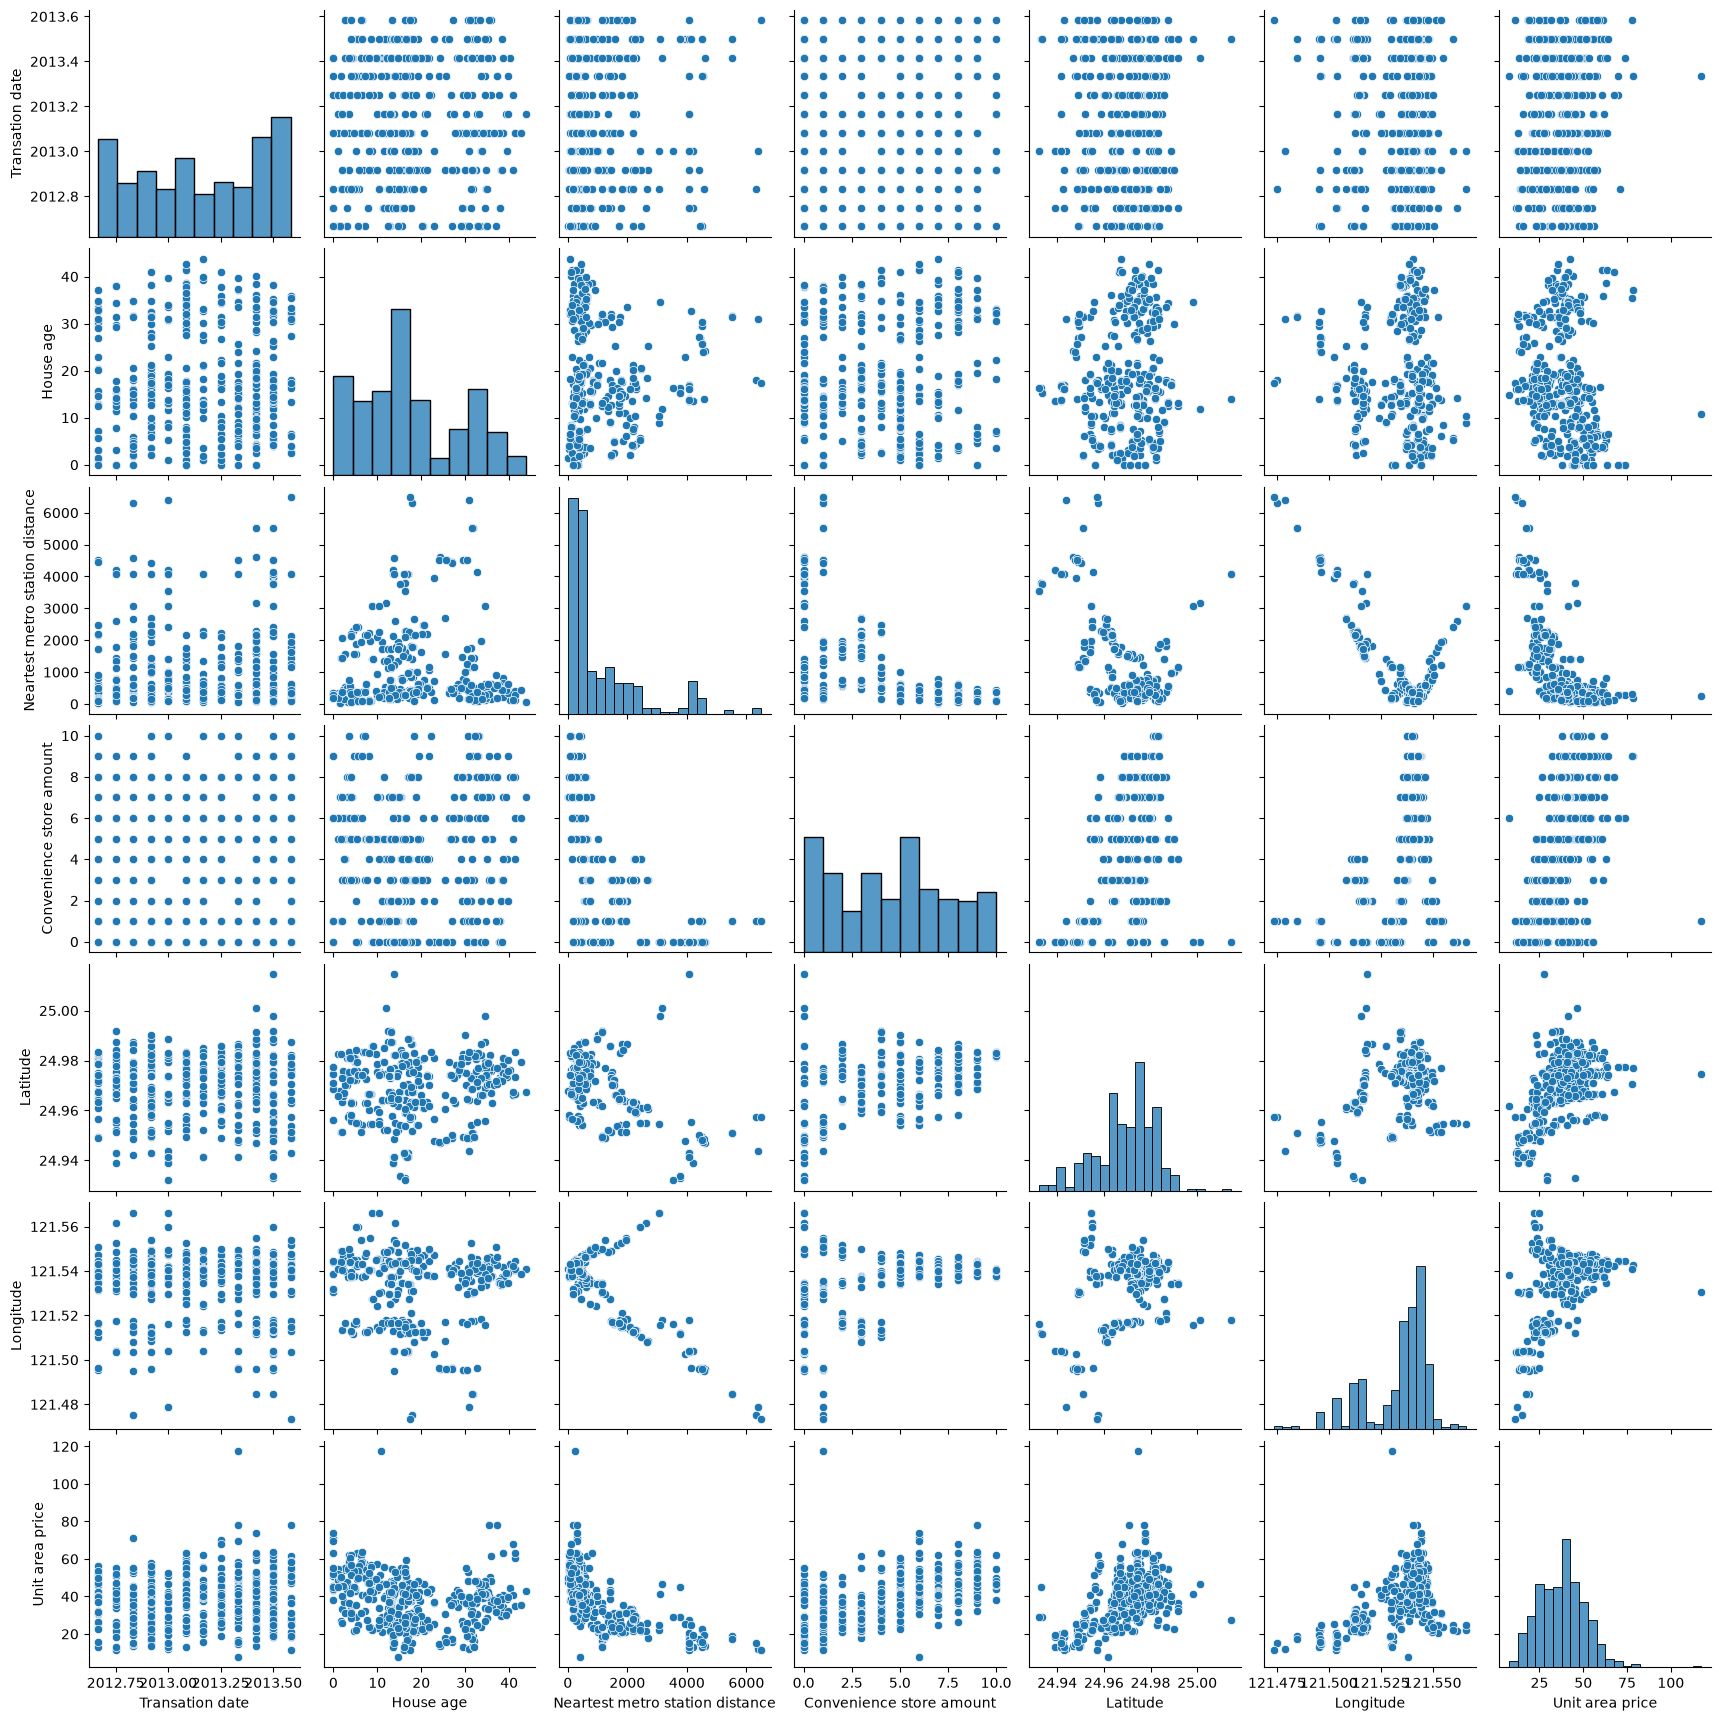

In [21]:
# plot all the data
sns.pairplot(df)

In [37]:
X = df.drop(columns=['Unit area price'])
y = df['Unit area price']            

In [38]:
# Display the X and y arrays
print(X, y)

     Transation date  House age  Neartest metro station distance  \
0         2012.91667   32.00000                         84.87882   
1         2012.91667   19.50000                        306.59470   
2         2013.58333   13.30000                        561.98450   
3         2013.50000   13.30000                        561.98450   
4         2012.83333    5.00000                        390.56840   
..               ...        ...                              ...   
409       2013.00000   13.70000                       4082.01500   
410       2012.66667    5.60000                         90.45606   
411       2013.25000   18.80000                        390.96960   
412       2013.00000    8.10000                        104.81010   
413       2013.50000    6.50000                         90.45606   

     Convenience store amount  Latitude  Longitude  
0                          10  24.98298  121.54024  
1                           9  24.98034  121.53951  
2                       

# ML Models

## Linear Regression

In [39]:
# Split the dataset
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 102)

In [40]:
# Show the rows and columns
X.shape, y.shape, X_train.shape, X_test.shape, y_train.shape, y_test.shape

((414, 6), (414,), (331, 6), (83, 6), (331,), (83,))

In [41]:
# Train the model
lr_model = LinearRegression().fit(X_train, y_train)

# Calculate the predicted values
y_pred_lr = lr_model.predict(X_test)

In [42]:
# Calculate the intercept and coefficient
print(lr_model.intercept_)
print(lr_model.coef_)

-16230.105697790032
[ 3.79659531e+00 -2.65318017e-01 -3.99274390e-03  1.17646617e+00
  2.48354775e+02  1.99760785e+01]


In [43]:
# Import evaluation metrics from scikit-learn
from sklearn.metrics import mean_squared_error, r2_score  

# Evaluate the model performance using test data
# y_test : actual/true values
# y_pred_lr : predicted values from the Linear Regression model

# Calculate Mean Squared Error (MSE)
# MSE measures the average squared difference between predicted and actual values.
# A lower MSE indicates a better fit.
mse_lr = mean_squared_error(y_test, y_pred_lr)

# Calculate R-squared Score (R²)
# R² explains the proportion of variance in the target variable
# that is predictable from the features (independent variables).
# R² ranges from 0 to 1; higher values indicate a better model.
r2_lr = r2_score(y_test, y_pred_lr)

# Print the results with formatting to 2 decimal places
print(f"Mean Squared Error (MSE): {mse_lr:.2f}")
print(f"R-squared Score (R²): {r2_lr:.2f}")

Mean Squared Error (MSE): 69.67
R-squared Score (R²): 0.65


In [44]:
print("MSE:", mse_lr)
print("RMSE:", mean_squared_error(y_test, y_pred_lr) ** 0.5)
print("R²:", r2_lr)

MSE: 69.66792562323232
RMSE: 8.346731433515297
R²: 0.6480421388038893


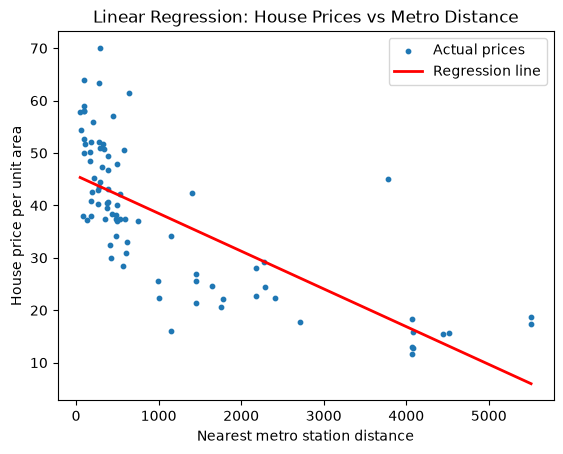

In [55]:
# !!!!!
from sklearn.linear_model import LinearRegression
import numpy as np

x = X_test[['Neartest metro station distance']]

model_line = LinearRegression()
model_line.fit(
    X_train[['Neartest metro station distance']],
    y_train
)

x_line = np.linspace(x.min().iloc[0], x.max().iloc[0], 100).reshape(-1, 1)
y_line = model_line.predict(x_line)

plt.scatter(
    X_test['Neartest metro station distance'],
    y_test,
    s=10,
    label='Actual prices'
)

plt.plot(x_line, y_line, color='red', linewidth=2, label='Regression line')

plt.xlabel('Nearest metro station distance')
plt.ylabel('House price per unit area')
plt.title('Linear Regression: House Prices vs Metro Distance')
plt.legend()
plt.show()

In [58]:
# Import evaluation metrics from scikit-learn
from sklearn.metrics import mean_squared_error, r2_score  

# Evaluate the model performance using test data
# y_test : actual/true values
# y_pred_lr : predicted values from the Linear Regression model

# Calculate Mean Squared Error (MSE)
# MSE measures the average squared difference between predicted and actual values.
# A lower MSE indicates a better fit.
mse_lr = mean_squared_error(y_test, y_pred_lr)

# Calculate R-squared Score (R²)
# R² explains the proportion of variance in the target variable
# that is predictable from the features (independent variables).
# R² ranges from 0 to 1; higher values indicate a better model.
r2_lr = r2_score(y_test, y_pred_lr)

# Print the results with formatting to 2 decimal places
print(f"Mean Squared Error (MSE): {mse_lr:.2f}")
print(f"R-squared Score (R²): {r2_lr:.2f}")

Mean Squared Error (MSE): 69.67
R-squared Score (R²): 0.65


In [59]:
print("MSE:", mse_lr)
print("RMSE:", mean_squared_error(y_test, y_pred_lr) ** 0.5)
print("R²:", r2_lr)

MSE: 69.66792562323232
RMSE: 8.346731433515297
R²: 0.6480421388038893


## Random Forest Regressor

In [56]:
from sklearn.ensemble import RandomForestRegressor

# Train the model
rf_model = RandomForestRegressor().fit(X_train, y_train)

# Calculate the predicted values
y_pred_rf = rf_model.predict(X_test)

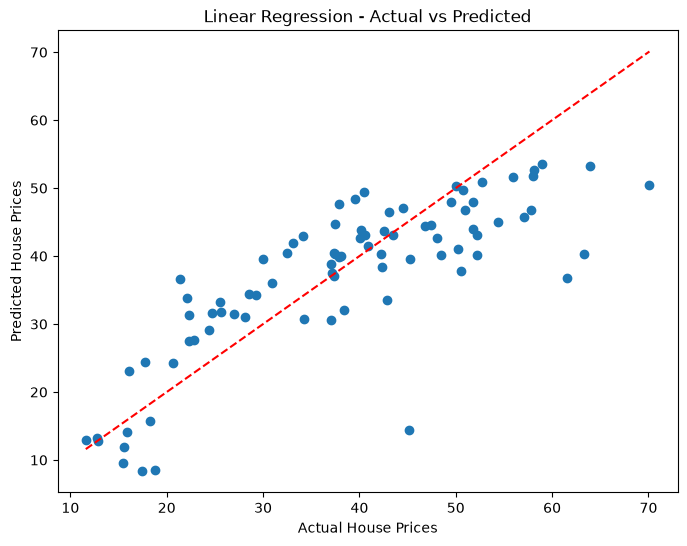

In [54]:

plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred_lr)
# one line below!!!!!!!
plt.plot([y_test.min(), y_test.max()],[y_test.min(), y_test.max()],'r--')

plt.xlabel('Actual House Prices')
plt.ylabel('Predicted House Prices')
plt.title('Linear Regression - Actual vs Predicted')

plt.show()

In [57]:
# !!!!!!!
from sklearn.metrics import mean_squared_error, r2_score

mse_rf = mean_squared_error(y_test, y_pred_rf)
rmse_rf = mean_squared_error(y_test, y_pred_rf) ** 0.5
r2_rf = r2_score(y_test, y_pred_rf)

print("MSE:", mse_rf)
print("RMSE:", rmse_rf)
print("R²:", r2_rf)

MSE: 34.60032878490975
RMSE: 5.882204415430473
R²: 0.8252013734171226


In [48]:
print(y.name)
print(y.head())
print(X.columns)

Unit area price
0   37.90000
1   42.20000
2   47.30000
3   54.80000
4   43.10000
Name: Unit area price, dtype: float64
Index(['Transation date', 'House age', 'Neartest metro station distance',
       'Convenience store amount', 'Latitude', 'Longitude'],
      dtype='str')


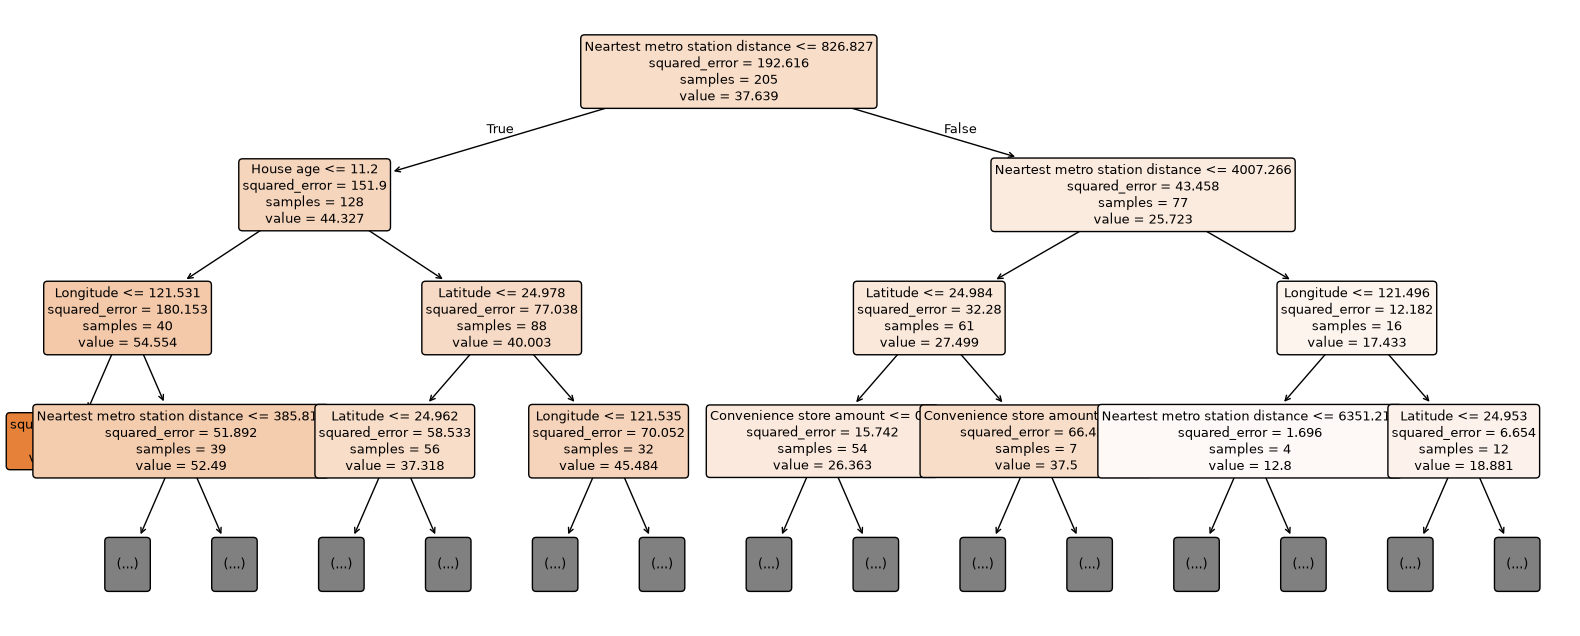

In [49]:
# Plot the Decision Tree
plt.figure(figsize = (20, 8))
plot_tree(rf_model.estimators_[0],filled = True, feature_names = X.columns.tolist(), 
          rounded = True,max_depth=3, fontsize = 9)
plt.show()